# CS 463 Project — Neural Networks

Continues `03_Modeling.ipynb` with the two neural networks from the Update 2
plan, using the same data, training rows, early-stopping split, and
evaluation:

6. MLP neural network with item embeddings
7. LSTM sequence model (RNN)

Run `03_Modeling.ipynb` first: this notebook adds its results to
`model_results_validation.csv` and `validation_predictions.parquet`.

In [1]:
import json
import os
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn

SEED = 42
HORIZON = 7

np.random.seed(SEED)
torch.manual_seed(SEED)
os.makedirs("models", exist_ok=True)

with open("feature_columns.json") as f:
    feature_columns = json.load(f)

id_columns = ["item_id", "cat_id", "date", "target_sales", "is_suspected_stockout"]

train = pd.read_parquet("train.parquet", columns=id_columns + feature_columns)
validation = pd.read_parquet("validation.parquet", columns=id_columns + feature_columns)

# Same training rows and early-stopping split as 03_Modeling.ipynb
train_clean = train[train["is_suspected_stockout"] == 0].reset_index(drop=True)

es_cutoff = train_clean["date"].quantile(0.9)
fit_part = train_clean[train_clean["date"] < es_cutoff].reset_index(drop=True)
es_part = train_clean[train_clean["date"] >= es_cutoff].reset_index(drop=True)

y_val = validation["target_sales"].to_numpy()
val_not_stockout = (validation["is_suspected_stockout"] == 0).to_numpy()

print("Fit rows:", f"{len(fit_part):,}", "| Early-stopping rows:", f"{len(es_part):,}")
print("Validation rows:", f"{len(validation):,}")

Fit rows: 2,133,389 | Early-stopping rows: 239,389
Validation rows: 842,328


In [2]:
# Results and predictions from 03_Modeling.ipynb
previous_results = pd.read_csv("model_results_validation.csv")
results = [
    row for row in previous_results.to_dict("records")
    if row["model"] not in ("MLP (item embeddings)", "LSTM (28-day sequence)")
]

val_predictions = pd.read_parquet("validation_predictions.parquet")


def report(name, y_pred, train_seconds=None):
    """Scores a model on the validation set and adds it to the results."""
    y_pred = np.maximum(0, np.asarray(y_pred, dtype=float))
    mask = val_not_stockout
    val_predictions[name] = y_pred.astype(np.float32)

    row = {
        "model": name,
        "MAE (all rows)": mean_absolute_error(y_val, y_pred),
        "MAE (non-stockout)": mean_absolute_error(y_val[mask], y_pred[mask]),
        "RMSE (all rows)": np.sqrt(mean_squared_error(y_val, y_pred)),
        "RMSE (non-stockout)": np.sqrt(mean_squared_error(y_val[mask], y_pred[mask])),
        "Bias (non-stockout)": y_pred[mask].mean() / y_val[mask].mean() - 1,
        "Train time (s)": train_seconds,
    }

    results.append(row)
    return pd.DataFrame([row]).round(3)


pd.DataFrame(results)[["model", "MAE (non-stockout)"]].round(3)

,model,MAE (non-stockout)
0,Baseline: sales 7 days earlier,1.437
1,Baseline: 28-day average,1.185
2,Linear Regression,1.203
3,Ridge (alpha=0.1),1.203
4,LASSO (alpha=0.01),1.203
5,Random Forest,1.176
6,XGBoost (squared error),1.175
7,"XGBoost (Tweedie, p=1.5)",1.157
8,Hurdle model (XGBoost + XGBoost),1.160


## 1. Neural network setup

The neural networks (MLP and LSTM) share this setup:

- **Item embedding:** each of the 3,049 products gets a learned 16-number
  vector, so the network can learn product-specific demand levels.
- **Inputs:** sales-based features are log-transformed (`log(1 + x)`) because
  they are highly skewed, then all features are standardized and clipped to
  ±10 standard deviations.
- **Output:** the network predicts log expected sales; the forecast is
  `exp(output)`, which is always positive.
- **Loss:** Poisson negative log-likelihood, suited to count data.
- **Optimizer:** Adam, learning rate 0.001, batch size 4,096, up to 8 epochs,
  stopping early when the early-stopping loss has not improved for 2 epochs.

In [3]:
# Products that launch during validation also need an embedding row
item_ids = sorted(set(train["item_id"]) | set(validation["item_id"]))
item_index = {item: i for i, item in enumerate(item_ids)}

sales_feature_columns = [
    c for c in feature_columns
    if c.startswith("sales_lag") or c.startswith("rolling_")
]


def prepare_features(df):
    X = df[feature_columns].copy()
    X[sales_feature_columns] = np.log1p(X[sales_feature_columns])
    return X.to_numpy(dtype=np.float32)


nn_scaler = StandardScaler().fit(prepare_features(fit_part))


def nn_inputs(df):
    # Clip extreme standardized values (e.g. huge % price changes on very cheap
    # items) so a few outliers cannot blow up the network's output
    X = np.clip(nn_scaler.transform(prepare_features(df)), -10, 10)
    return {
        "X": X.astype(np.float32),
        "item": df["item_id"].map(item_index).to_numpy(dtype=np.int64),
        "y": df["target_sales"].to_numpy(dtype=np.float32),
    }


nn_fit = nn_inputs(fit_part)
nn_es = nn_inputs(es_part)
nn_val = nn_inputs(validation)

In [4]:
def fit_network(model, make_batch, n_fit, n_es, epochs=8, batch_size=4096, patience=2):
    """Trains with Adam + Poisson loss, keeping the epoch with the best early-stopping loss."""
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.PoissonNLLLoss(log_input=True)
    rng = np.random.default_rng(SEED)

    best_loss = np.inf
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()
        order = rng.permutation(n_fit)

        for start in range(0, n_fit, batch_size):
            inputs, y = make_batch("fit", order[start:start + batch_size])
            optimizer.zero_grad()
            loss = loss_fn(model(*inputs), y)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            es_loss = np.mean([
                loss_fn(model(*inputs), y).item()
                for inputs, y in (
                    make_batch("es", np.arange(s, min(s + 16384, n_es)))
                    for s in range(0, n_es, 16384)
                )
            ])

        print(f"Epoch {epoch + 1}: early-stopping Poisson loss = {es_loss:.4f}")

        if es_loss < best_loss:
            best_loss = es_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    model.load_state_dict(best_state)
    return model


# Highest log expected sales allowed: exp(8) is about 3,000 units a day,
# far above any real day in this store
MAX_LOG_SALES = 8.0


def predict_network(model, make_batch, n):
    model.eval()
    with torch.no_grad():
        return np.concatenate([
            torch.exp(
                model(*make_batch("val", np.arange(s, min(s + 16384, n)))[0])
                .clamp(max=MAX_LOG_SALES)
            ).numpy()
            for s in range(0, n, 16384)
        ])

## 2. MLP (multilayer perceptron)

| Layer | Details |
|---|---|
| Input | 47 standardized features + 16-dim item embedding = 63 values |
| Hidden 1 | 128 units, ReLU, dropout 0.1 |
| Hidden 2 | 64 units, ReLU |
| Output | 1 unit (log expected sales) |

In [5]:
class DemandMLP(nn.Module):
    def __init__(self, n_features, n_items, embedding_dim=16):
        super().__init__()
        self.item_embedding = nn.Embedding(n_items, embedding_dim)
        self.layers = nn.Sequential(
            nn.Linear(n_features + embedding_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, X, item):
        x = torch.cat([X, self.item_embedding(item)], dim=1)
        return self.layers(x).squeeze(1)


mlp_data = {"fit": nn_fit, "es": nn_es, "val": nn_val}


def mlp_batch(split, idx):
    d = mlp_data[split]
    inputs = (torch.from_numpy(d["X"][idx]), torch.from_numpy(d["item"][idx]))
    return inputs, torch.from_numpy(d["y"][idx])


torch.manual_seed(SEED)
mlp_model = DemandMLP(len(feature_columns), len(item_ids))

start = time.time()
mlp_model = fit_network(mlp_model, mlp_batch, len(fit_part), len(es_part))
mlp_seconds = time.time() - start

report("MLP (item embeddings)", predict_network(mlp_model, mlp_batch, len(validation)), mlp_seconds)

Epoch 1: early-stopping Poisson loss = -0.8154
Epoch 2: early-stopping Poisson loss = -0.8335
Epoch 3: early-stopping Poisson loss = -0.8345
Epoch 4: early-stopping Poisson loss = -0.8464
Epoch 5: early-stopping Poisson loss = -0.8581
Epoch 6: early-stopping Poisson loss = -0.8593
Epoch 7: early-stopping Poisson loss = -0.8625
Epoch 8: early-stopping Poisson loss = -0.8617


,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,MLP (item embeddings),1.272,1.181,2.732,2.297,0.005,33.03


## 3. LSTM sequence model (RNN)

Instead of hand-made lag and rolling features, the LSTM reads the raw sequence
of the last 28 days of sales that are known on the order date (days
`t − 34` to `t − 7`) and learns its own summary of recent demand.

| Part | Details |
|---|---|
| Sequence input | 28 days of `log(1 + sales)`, ending `HORIZON` days before the target date |
| LSTM | 1 layer, 64 hidden units |
| Other inputs | Known-in-advance features (price, calendar, events, department) + 16-dim item embedding |
| Head | 64 units, ReLU → 1 output (log expected sales) |
| Training rows | 1,000,000 (random sample, to keep training time reasonable) |

The sales sequences are read from the raw daily sales table, so every
calendar day is present.

In [6]:
SEQ_LEN = 28

raw_sales = pd.read_csv("sales_train_validation.csv")
raw_sales = raw_sales[raw_sales["store_id"] == "CA_1"].set_index("item_id")
day_cols = [c for c in raw_sales.columns if c.startswith("d_")]

# Rows = products (same order as the embedding), columns = days d_1 ... d_1913
sales_matrix = np.log1p(
    raw_sales.loc[item_ids, day_cols].to_numpy(dtype=np.float32)
)

calendar = pd.read_csv("calendar.csv", usecols=["date", "d"])
day_index = pd.Series(
    np.arange(len(calendar)),
    index=pd.to_datetime(calendar["date"])
)

known_columns = [c for c in feature_columns if c not in sales_feature_columns]
known_positions = [feature_columns.index(c) for c in known_columns]

lstm_fit_rows = fit_part.sample(1_000_000, random_state=SEED).index.to_numpy()


def lstm_inputs(df, nn_d, rows=None):
    rows = np.arange(len(df)) if rows is None else rows
    return {
        "known": nn_d["X"][rows][:, known_positions],
        "item": nn_d["item"][rows],
        "day": df["date"].map(day_index).to_numpy()[rows],
        "y": nn_d["y"][rows],
    }


lstm_data = {
    "fit": lstm_inputs(fit_part, nn_fit, lstm_fit_rows),
    "es": lstm_inputs(es_part, nn_es),
    "val": lstm_inputs(validation, nn_val),
}

# Window offsets: oldest day first, newest day = target day - HORIZON
window_offsets = np.arange(-(HORIZON + SEQ_LEN - 1), -HORIZON + 1)

print("Earliest window start (day index):", (lstm_data["fit"]["day"] + window_offsets[0]).min())

Earliest window start (day index): 0


In [7]:
class DemandLSTM(nn.Module):
    def __init__(self, n_known, n_items, embedding_dim=16, hidden=64):
        super().__init__()
        self.item_embedding = nn.Embedding(n_items, embedding_dim)
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_known + embedding_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, sequence, known, item):
        _, (h, _) = self.lstm(sequence)
        x = torch.cat([h[-1], known, self.item_embedding(item)], dim=1)
        return self.head(x).squeeze(1)


def lstm_batch(split, idx):
    d = lstm_data[split]
    days = d["day"][idx][:, None] + window_offsets
    sequence = sales_matrix[d["item"][idx][:, None], days][:, :, None]
    inputs = (
        torch.from_numpy(sequence),
        torch.from_numpy(d["known"][idx]),
        torch.from_numpy(d["item"][idx]),
    )
    return inputs, torch.from_numpy(d["y"][idx])


torch.manual_seed(SEED)
lstm_model = DemandLSTM(len(known_columns), len(item_ids))

start = time.time()
lstm_model = fit_network(lstm_model, lstm_batch, len(lstm_fit_rows), len(es_part))
lstm_seconds = time.time() - start

report("LSTM (28-day sequence)", predict_network(lstm_model, lstm_batch, len(validation)), lstm_seconds)

Epoch 1: early-stopping Poisson loss = -0.7770
Epoch 2: early-stopping Poisson loss = -0.8035
Epoch 3: early-stopping Poisson loss = -0.8153
Epoch 4: early-stopping Poisson loss = -0.8403
Epoch 5: early-stopping Poisson loss = -0.8102
Epoch 6: early-stopping Poisson loss = -0.8493
Epoch 7: early-stopping Poisson loss = -0.8513
Epoch 8: early-stopping Poisson loss = -0.8527


,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,LSTM (28-day sequence),1.233,1.17,2.471,2.285,0.009,315.78


## 4. Save models

| File | Contents |
|---|---|
| `models/mlp.pt` | MLP weights |
| `models/lstm.pt` | LSTM weights |
| `models/nn_preprocessing.joblib` | Feature scaler, item list, and column lists needed to prepare inputs |

To reload: create the model with the same class, then
`model.load_state_dict(torch.load("models/mlp.pt"))`.

In [8]:
torch.save(mlp_model.state_dict(), "models/mlp.pt")
torch.save(lstm_model.state_dict(), "models/lstm.pt")

joblib.dump(
    {
        "scaler": nn_scaler,
        "item_ids": item_ids,
        "feature_columns": feature_columns,
        "sales_feature_columns": sales_feature_columns,
        "known_columns": known_columns,
        "seq_len": SEQ_LEN,
        "horizon": HORIZON,
    },
    "models/nn_preprocessing.joblib"
)

val_predictions.to_parquet("validation_predictions.parquet", index=False)

print(sorted(os.listdir("models")))

['.ipynb_checkpoints', 'hurdle_classifier.json', 'hurdle_regressor.json', 'lasso.joblib', 'linear_regression.joblib', 'lstm.pt', 'mlp.pt', 'nn_preprocessing.joblib', 'random_forest.joblib', 'ridge.joblib', 'xgb_squared_error.json', 'xgb_tweedie.json']


## 5. Results on the validation set (all models)

Lower MAE and RMSE are better. Bias near 0% is better: negative bias means the
model under-forecasts demand, which leads to stockouts.

In [9]:
results_table = (
    pd.DataFrame(results)
    .sort_values("MAE (non-stockout)")
    .reset_index(drop=True)
)

results_table.to_csv("model_results_validation.csv", index=False)

results_table.style.format({
    "MAE (all rows)": "{:.3f}",
    "MAE (non-stockout)": "{:.3f}",
    "RMSE (all rows)": "{:.3f}",
    "RMSE (non-stockout)": "{:.3f}",
    "Bias (non-stockout)": "{:+.1%}",
    "Train time (s)": "{:.0f}",
}, na_rep="—")

,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,"XGBoost (Tweedie, p=1.5)",1.195,1.157,2.472,2.270,-0.1%,16
1,Hurdle model (XGBoost + XGBoost),1.209,1.160,2.484,2.263,+0.5%,39
2,LSTM (28-day sequence),1.233,1.170,2.471,2.285,+0.9%,316
3,XGBoost (squared error),1.211,1.175,2.556,2.292,+1.2%,7
4,Random Forest,1.212,1.176,2.437,2.322,+1.0%,11
5,MLP (item embeddings),1.272,1.181,2.732,2.297,+0.5%,33
6,Baseline: 28-day average,1.128,1.185,2.551,2.527,-9.3%,—
7,LASSO (alpha=0.01),1.158,1.203,2.427,2.408,+1.6%,13
8,Linear Regression,1.159,1.203,2.428,2.408,+1.7%,2
9,Ridge (alpha=0.1),1.159,1.203,2.428,2.408,+1.7%,12


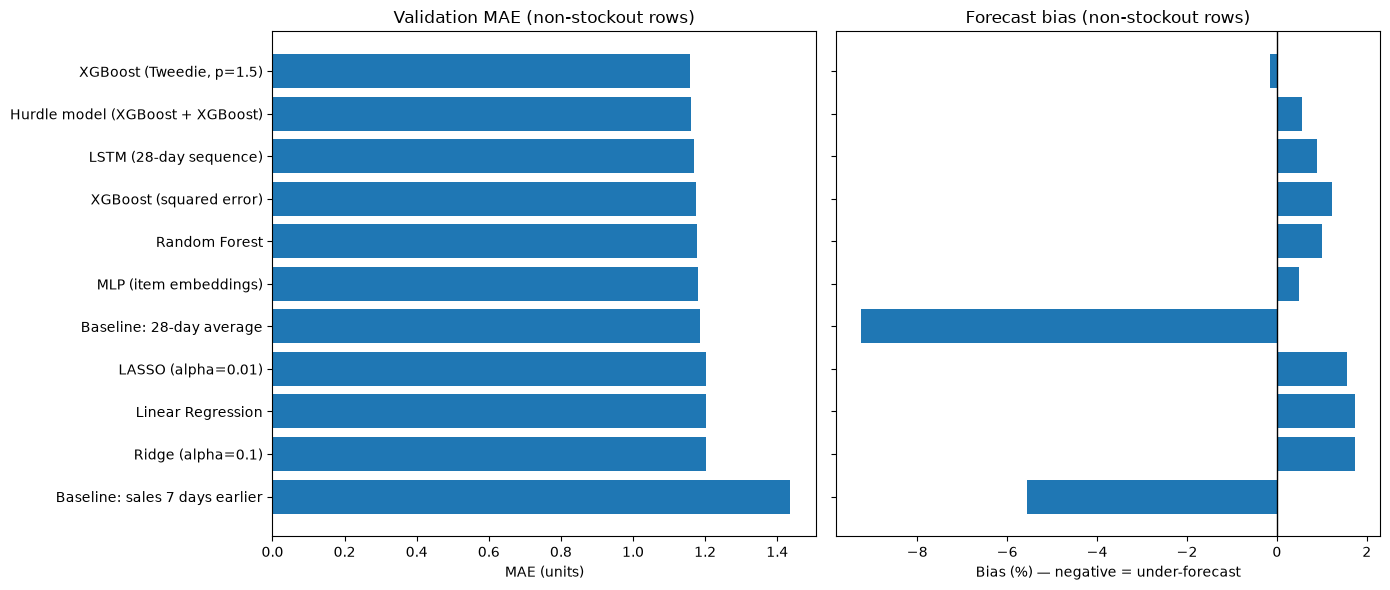

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

ordered = results_table.sort_values("MAE (non-stockout)", ascending=False)

axes[0].barh(ordered["model"], ordered["MAE (non-stockout)"])
axes[0].set_title("Validation MAE (non-stockout rows)")
axes[0].set_xlabel("MAE (units)")

axes[1].barh(ordered["model"], ordered["Bias (non-stockout)"] * 100)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Forecast bias (non-stockout rows)")
axes[1].set_xlabel("Bias (%) — negative = under-forecast")

plt.tight_layout()
plt.show()